In [1]:
# Cell 1: load sample, fix labels, split
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, joblib
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

df = pd.read_parquet("../data/sample.parquet")
df["Label"] = df["Label"].str.replace("�", "-", regex=False)   # fix garbled web attack names

X = df.drop(columns=["Label", "is_attack"])
y = df["Label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42)
print(X_train.shape, X_test.shape)

(163930, 78) (70257, 78)


In [2]:
# Cell 2: train Random Forest (multi-class)
rf = RandomForestClassifier(
    n_estimators=100, class_weight="balanced_subsample",
    n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
pred = rf.predict(X_test)
print(classification_report(y_test, pred, digits=3, zero_division=0))

                            precision    recall  f1-score   support

                    BENIGN      0.996     0.998     0.997     15000
                       Bot      0.995     0.976     0.985       584
                      DDoS      1.000     1.000     1.000     15000
             DoS GoldenEye      0.998     0.998     0.998      3086
                  DoS Hulk      0.998     0.999     0.999     15000
          DoS Slowhttptest      0.996     0.992     0.994      1569
             DoS slowloris      0.996     0.995     0.995      1616
               FTP-Patator      1.000     1.000     1.000      1779
                Heartbleed      1.000     1.000     1.000         3
              Infiltration      1.000     0.636     0.778        11
                  PortScan      0.999     0.998     0.999     15000
               SSH-Patator      0.999     0.998     0.998       966
  Web Attack - Brute Force      0.734     0.828     0.778       441
Web Attack - Sql Injection      0.667     0.333

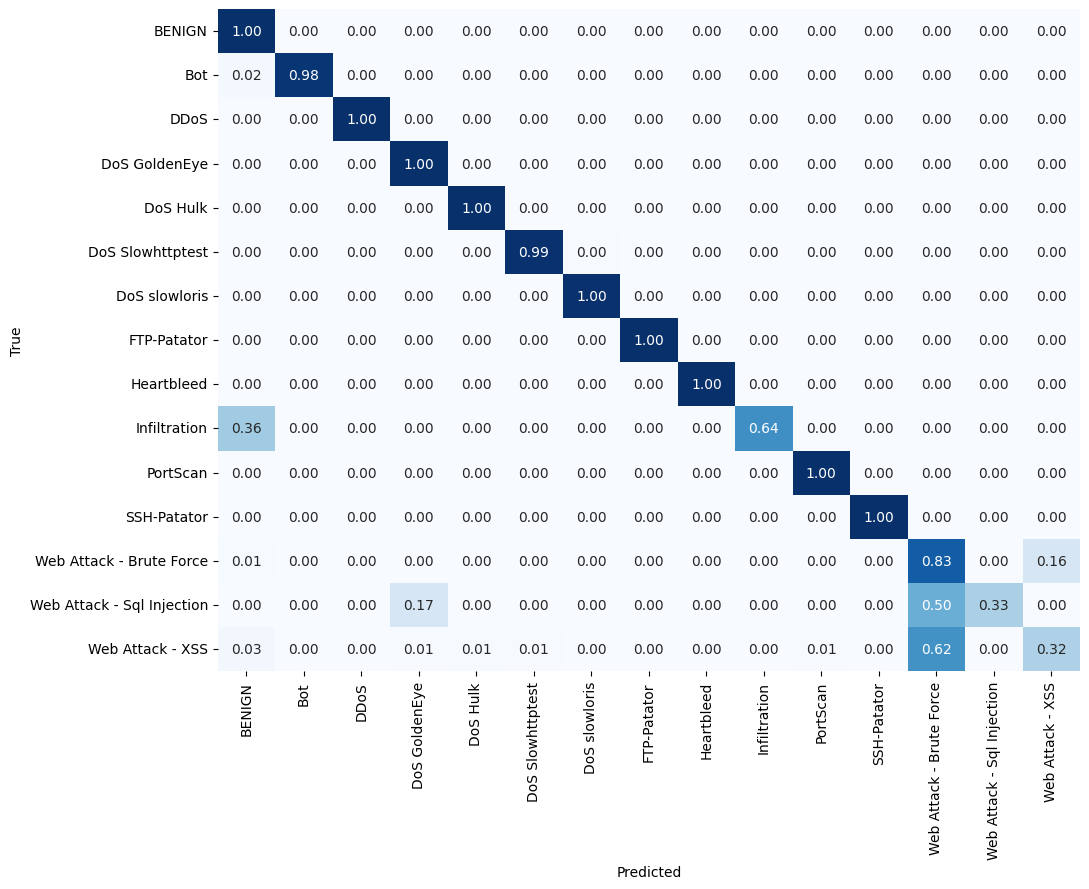

In [3]:
# Cell 3: confusion matrix (row-normalised = recall per class)
labels = sorted(y.unique())
cm = confusion_matrix(y_test, pred, labels=labels, normalize="true")
plt.figure(figsize=(11,9))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=labels, yticklabels=labels, cbar=False)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.tight_layout(); plt.show()

In [4]:
# Cell 4: binary view - attack vs benign
true_bin = (y_test != "BENIGN").astype(int)
pred_bin = (pd.Series(pred, index=y_test.index) != "BENIGN").astype(int)

tp = ((true_bin==1) & (pred_bin==1)).sum()
fn = ((true_bin==1) & (pred_bin==0)).sum()
fp = ((true_bin==0) & (pred_bin==1)).sum()
tn = ((true_bin==0) & (pred_bin==0)).sum()

print("Attack recall (detection rate):", round(tp/(tp+fn), 4))
print("False alarm rate:", round(fp/(fp+tn), 4))
print("Missed attacks:", fn, "| False alarms:", fp)

Attack recall (detection rate): 0.999
False alarm rate: 0.0016
Missed attacks: 58 | False alarms: 24


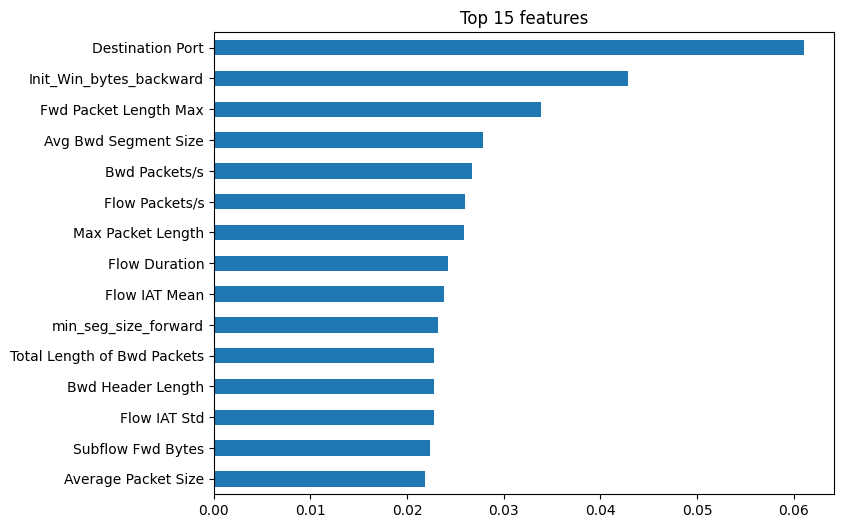

['../src/rf_baseline.joblib']

In [5]:
# Cell 5: top features + save model
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
imp.head(15).sort_values().plot(kind="barh", figsize=(8,6), title="Top 15 features")
plt.show()

import os
os.makedirs("../src", exist_ok=True)
joblib.dump({"model": rf, "features": list(X.columns)}, "../src/rf_baseline.joblib")